# Project Purple Flight Simulation and Motor Optimisation

## Workflow

1. Develop design in OpenRockets
2. Copy dimensions into this script (verify the rocket looks correct including RASAero)
3. Script generates rocket aerodynamic data for the rocket from RASAeroII
4. Script generates airfoil aerodynamic data from xFoil
5. Define environment, assumptions and constraints
5. Script determines the optimal fixed thrust, commercial motor and variable thrust motor/thrust profile to maximise altitude

## Usage Notes

Depending on options used it is likely you'll need both xFoil and RASAeroII installed and configured in the correct paths. If these are not installed/configured correctly when you run the program instructions for correct installation/configuration will be provided within error messages. The RASAeroII scripting requires briefly taking control of the GUI to navigate the program. This control is limited to the RASAeroII window only and has no other control on the computer. This process can take up to 2 minutes, please give it time to finish on its own.

Please ensure you change the name of the rocket in the define optimiser code block otherwise you'll always simulate the same rocket.

During variable thrust optimisation you can open the progress plots in a separate window and they will be updated throughout the running (this may take over an hour) to visually show progress. If you're image viewer support automatic re-rendering on save (like VSCode) they'll visually update as the program runs.

In [1]:
import faulthandler

_fault_log = open("kernel-fault.log", "a", buffering=1)
faulthandler.enable(file=_fault_log, all_threads=True)

print("Crash logging enabled")

# Install requirements (python modules) and import
try:
    from model.rocket import *
except ImportError:
    get_ipython().run_line_magic("pip", "install -r ./requirements.txt") # type: ignore
    from model.rocket import *

# hide warnings
# import numpy as np
# np.seterr("ignore")
# import warnings
# warnings.simplefilter("ignore")

from IPython.core.display import Image, display
from model.util.output.info import Table

Crash logging enabled


C:\Users\rufus\AppData\Local\Temp\ipykernel_31864\3901275162.py:21: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import Image, display


### Save option

Whether to save plots and summaries of simulated flight.

Setting this option to ```True``` is recommended.

The optimal variable thrust curve RASP.ENG thrust curve files will be saved irrespective of this option.

All saved files will print a useful dialogue when saved with their save location.

In [2]:
save = False

### Define launch environment, launcher and aerodynamic simulation options

In [3]:
AFC = EnvironmentGenerator(
    latitude=52.81100146975089,
    longitude=-4.123811984367132,
    elevation=9,
)
AFC.set_atmospheric_model(
    wind_speed=5,
    wind_bearing=90
)

launcher = LauncherGenerator(
    length=12,
    heading=0,
    inclination=90
)

rasaero_config = RASAeroConfig(
    surface="Polished",
    use_modified_barrowman=True,
    turbulence_only_flight=False
)

### Define 57mm Concept

* With original assumed lengths and mass

Selected: Cesaroni-M2020
Using cached RASAero aero data
Loaded aero data: c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\data\rocket\Project-Purple-57mm\aeroData.csv


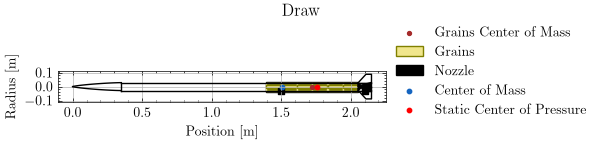

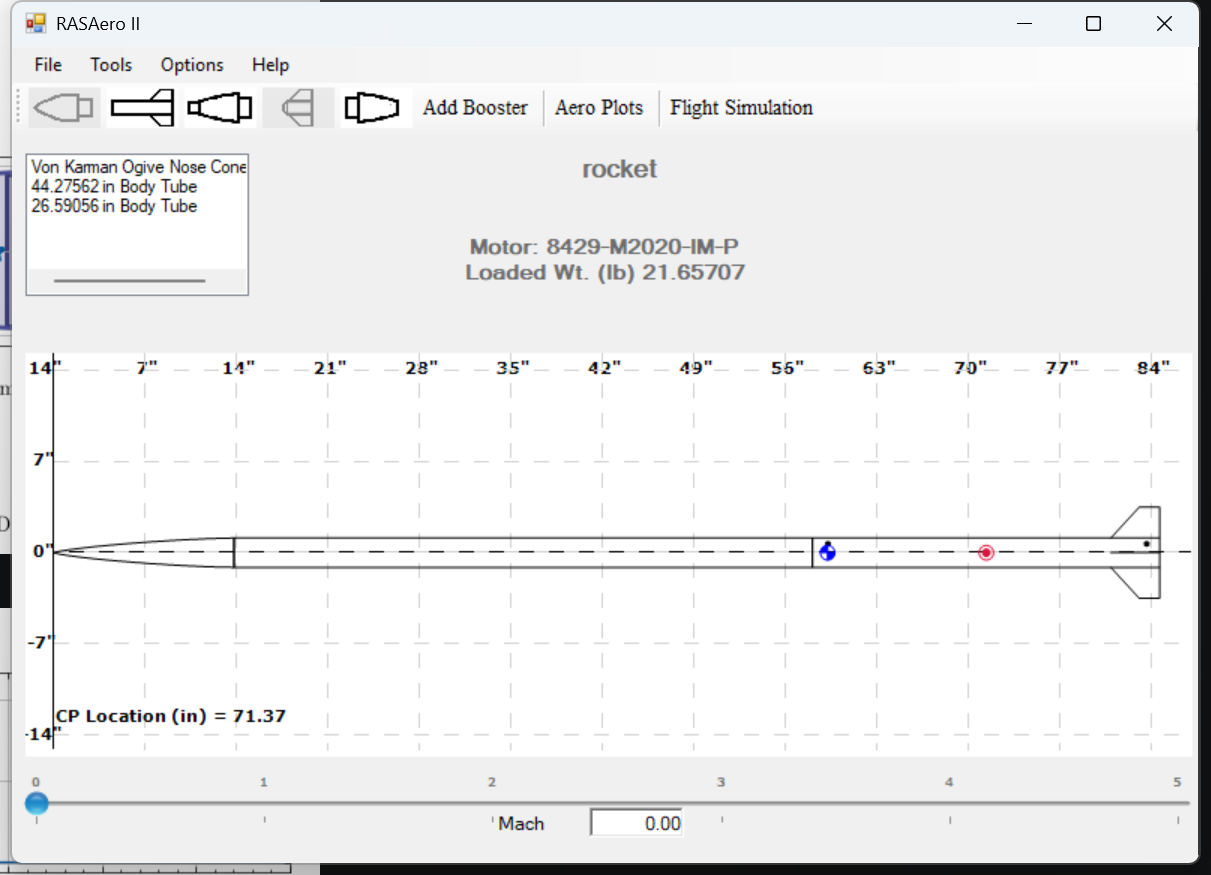

In [4]:
rocket_57mm = RocketGenerator(
    name="Project-Purple-57mm",
    diameter=57 / 1000,
    mass_without_motor=2790 / 1000,
    inertia_without_motor=(0.002919, 0.002919, 0.726925), # estimated from OpenRocket
    center_of_mass_without_motor=913 / 1000,
    aero="estimate"
)

rocket_57mm.add_rail_buttons(
    upper_button_position=1500 / 1000,
    lower_button_position=2100 / 1000,
    angular_position=45,
    diameter=9.7 / 1000,
    height=7.5 / 1000
)

rocket_57mm.add_nose(
    length=350 / 1000,
    kind="von karman",
    blunt_radius=2 / 1000
)

rocket_57mm.add_trapezoidal_fins(
    n=4,
    root_chord=95 / 1000,
    tip_chord=40 / 1000,
    span=60 / 1000,
    position=2055 / 1000,
    sweep_length=55 / 1000,
    # airfoil=("./data/rocket/ManSEDS L4C/NACA0012-radians.txt", "radians"),
    leading_edge_radius=1 / 1000,
    thickness=5 / 1000,
    airfoil_type="Subsonic NACA",
)

rocket_57mm.add_parachute(
    name="Main Parachute",
    cd=2.2,
    diameter=1524 / 1000,
    trigger="altitude",
    deploy_altitude=300,
)

rocket_57mm.add_parachute(
    name="Drogue Parachute",
    cd=1.6,
    diameter=305 / 1000,
    trigger="apogee",
)

rocket_57mm.add_motor(
    motor_name="M2020",
    position=2150 / 1000,
    nozzle_diameter=33.38 / 1000
)

flight_generator_57mm = FlightGenerator(
    rocket=rocket_57mm,
    env=AFC,
    launcher=launcher,
    rasaero_config=rasaero_config
)

flight_generator_57mm.ideal().rocket.plots.draw(show=True, save=save)
display(Image(filename=f"data/rocket/{flight_generator_57mm.name}/rocket.png"))

### Define 68mm Concept

* With original assumed masses and length

Selected: Cesaroni-M2020
Using cached RASAero aero data
Loaded aero data: c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\data\rocket\Project-Purple-68mm\aeroData.csv


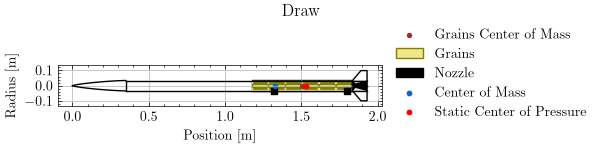

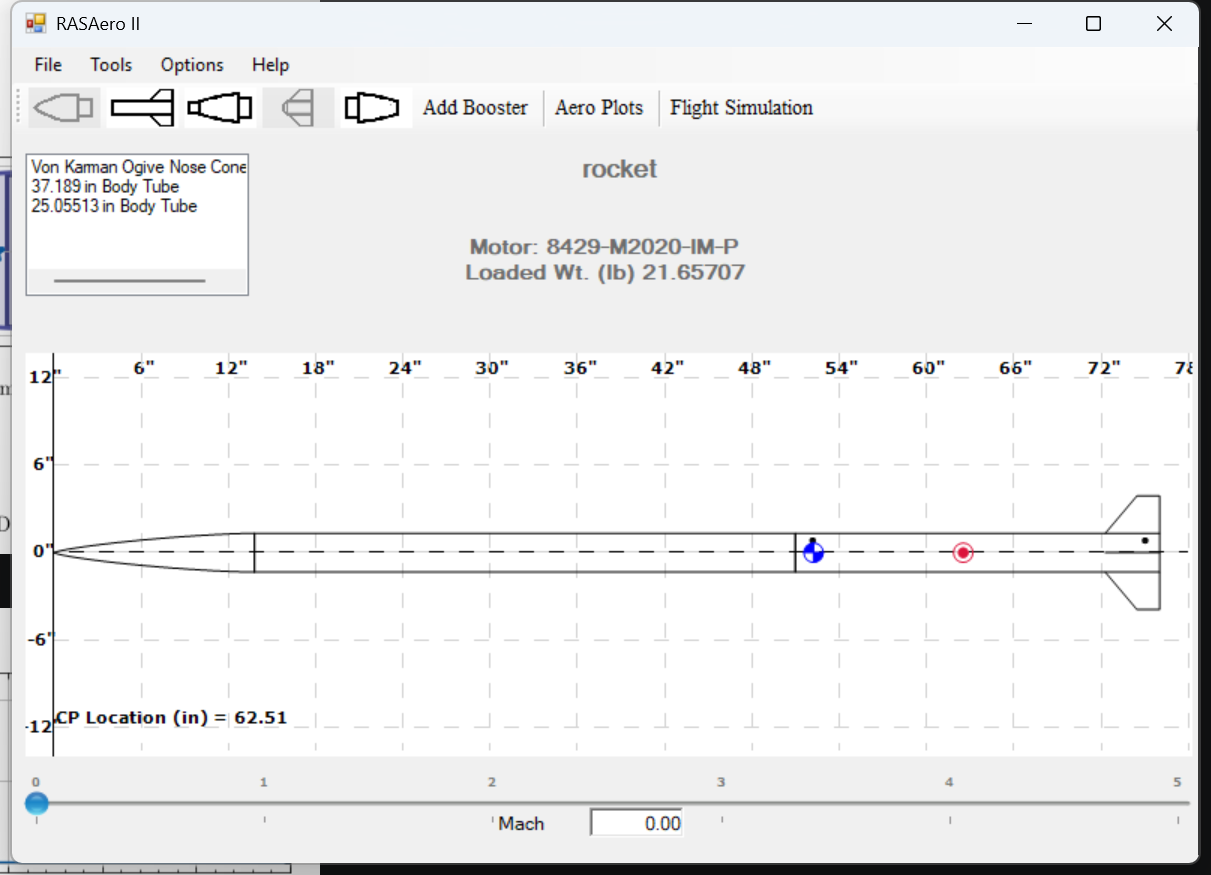

In [5]:
rocket_68mm = RocketGenerator(
    name="Project-Purple-68mm",
    diameter=68 / 1000,
    mass_without_motor=2790 / 1000,
    inertia_without_motor=(0.002919, 0.002919, 0.726925), # estimated from OpenRocket
    center_of_mass_without_motor=838 / 1000,
    aero="estimate",
)

rocket_68mm.add_rail_buttons(
    upper_button_position=1320 / 1000,
    lower_button_position=1800 / 1000,
    angular_position=45,
    diameter=9.7 / 1000,
    height=7.5 / 1000
)

rocket_68mm.add_nose(
    length=350 / 1000,
    kind="von karman",
    blunt_radius=2 / 1000,
)

rocket_68mm.add_trapezoidal_fins(
    n=4,
    root_chord=95 / 1000,
    tip_chord=40 / 1000,
    span=65 / 1000,
    position=1836 / 1000,
    sweep_length=55 / 1000,
    # airfoil=("./data/rocket/ManSEDS L4C/NACA0012-radians.txt", "radians"),
    leading_edge_radius=1 / 1000,
    thickness=5 / 1000,
    airfoil_type="Subsonic NACA"
)

rocket_68mm.add_parachute(
    name="Main Parachute",
    cd=2.2,
    diameter=1524 / 1000,
    trigger="altitude",
    deploy_altitude=300,
)

rocket_68mm.add_parachute(
    name="Drogue Parachute",
    cd=1.6,
    diameter=305 / 1000,
    trigger="apogee",
)

rocket_68mm.add_motor(
    motor_name="M2020",
    position=1931 / 1000,
    nozzle_diameter=33.38 / 1000
)

flight_generator_68mm = FlightGenerator(
    rocket=rocket_68mm,
    env=AFC,
    launcher=launcher,
    rasaero_config=rasaero_config
)

flight_generator_68mm.ideal().rocket.plots.draw(show=True, save=save)
display(Image(filename=f"data/rocket/{flight_generator_68mm.name}/rocket.png"))

### 75mm Initial Concept

* Based on preliminary engine sizing

Selected: Cesaroni-M2020
Using cached RASAero aero data
Loaded aero data: c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\data\rocket\Project-Purple-75mm\aeroData.csv


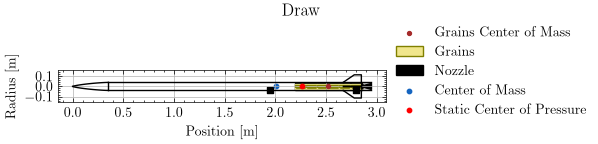

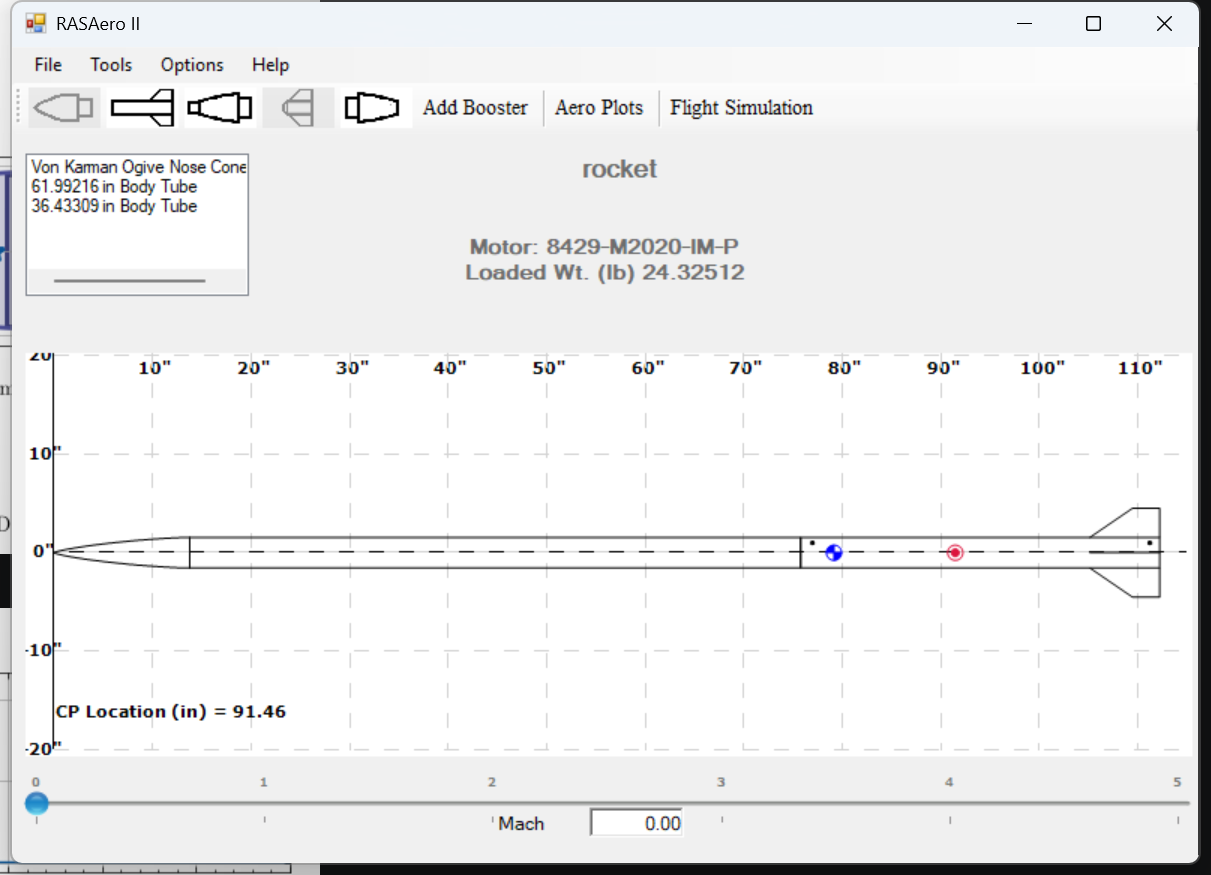

In [6]:
rocket_75mm = RocketGenerator(
    name="Project-Purple-75mm",
    diameter=79.1 / 1000,
    mass_without_motor=4000 / 1000,
    inertia_without_motor=(0.002919, 0.002919, 0.726925), # estimated from OpenRocket
    center_of_mass_without_motor=1087 / 1000,
    aero="estimate",
)

rocket_75mm.add_rail_buttons(
    upper_button_position=1950 / 1000,
    lower_button_position=2800 / 1000,
    angular_position=45,
    diameter=9.7 / 1000,
    height=7.5 / 1000
)

rocket_75mm.add_nose(
    length=350 / 1000,
    kind="von karman",
    blunt_radius=2 / 1000,
)

rocket_75mm.add_trapezoidal_fins(
    n=4,
    root_chord=180 / 1000,
    tip_chord=70 / 1000,
    span=75 / 1000,
    position=2670 / 1000,
    sweep_length=110 / 1000,
    leading_edge_radius=1 / 1000,
    thickness=5 / 1000,
    airfoil_type="Subsonic NACA"
)

rocket_75mm.add_parachute(
    name="Main Parachute",
    cd=2.2,
    diameter=1524 / 1000,
    trigger="altitude",
    deploy_altitude=300,
)

rocket_75mm.add_parachute(
    name="Drogue Parachute",
    cd=1.6,
    diameter=305 / 1000,
    trigger="apogee",
)

rocket_75mm.add_motor(
    motor_name="M2020",
    position=2950 / 1000,
    nozzle_diameter=33.38 / 1000
)

flight_generator_75mm = FlightGenerator(
    rocket=rocket_75mm,
    env=AFC,
    launcher=launcher,
    rasaero_config=rasaero_config
)

flight_generator_75mm.ideal().rocket.plots.draw(show=True, save=save)
display(Image(filename=f"data/rocket/{flight_generator_75mm.name}/rocket.png"))

### Define Optimiser, Constraints and Assumptions

Change the flight generator within the optimiser below to simulate different rockets.

In [7]:
optimiser = MotorOptimisation(
    flight=flight_generator_75mm, # ! Change rocket to simulate here
)

constraints = Constraints(
    min_thrust=100,
    max_thrust=2000,
    min_speed_out_of_rail=20,
    total_impulse=10239
)

assumptions = Assumptions(
    motor_total_mass=12,
    motor_prop_mass=5.5,
    motor_diameter=76.1 / 1000,
    motor_length=2260 / 1000
)

print(f"Optimiser using {optimiser.name} rocket")

Optimiser using Project-Purple-75mm rocket


### Commercial Motor Selection

This ignores motor diameter and length and only consider the thrust curve and mass of commerical motors.

In [8]:
cots_table: Table | None = None

out = optimiser.find_optimal_motor(impulseClass="M")
if out is None:
    print("No valid commerical motors found")
else:
    best_flight, best_rocket, out_table = out
    cots_table += out_table

assert cots_table
cots_table.show(sort_column="Altitude [km]", sort_ascending=False)

find optimal motor [                    ] 0.00% (elapsed: 0s - remaining: 0s)
find optimal motor [                    ] 0.00% (elapsed: 0s - remaining: 0s) - motor: M1200-SF - impulse: 5184.54Ns - apogee: 5.18km
find optimal motor [                    ] 1.09% (elapsed: 0s - remaining: 1m 19s) - motor: M1355RT - impulse: 5353.44Ns - apogee: 5.32km
find optimal motor [                    ] 2.17% (elapsed: 1s - remaining: 59s) - motor: M1350W - impulse: 5179.47Ns - apogee: 5.26km
find optimal motor [                    ] 3.26% (elapsed: 1s - remaining: 55s) - motor: M1101WH - impulse: 5199.60Ns - apogee: 5.30km
find optimal motor [                    ] 4.35% (elapsed: 2s - remaining: 56s) - motor: M2225WS - impulse: 5184.05Ns - apogee: 5.20km
find optimal motor [#                   ] 5.43% (elapsed: 3s - remaining: 54s) - motor: M1500G - impulse: 5217.24Ns - apogee: 5.28km
find optimal motor [#                   ] 6.52% (elapsed: 3s - remaining: 51s) - motor: M1560-WT - impulse: 5322.28Ns

### Fixed Thrust Optimisation

Finds the optimal single fixed thrust to achieve the highest altitude within a fixed specific impulse.

In [9]:
fixed_table: Table | None = None

out = optimiser.optimise_fixed_thrust(
    constraints=constraints,
    assumptions=assumptions,
    verbose=False,
)
if out is None:
    print("Not valid fixed thrust found")
else:
    best_flight, best_rocket, out_table = out
    fixed_table += out_table

assert fixed_table
fixed_table.show(sort_column="Altitude [km]", sort_ascending=False)

                              Name  Altitude [km]  Maximum Mach  System Efficiency [%]  Total Impulse [Ns]  Maximum Thrust [N]  Average Thrust [N]  Burn Time [s]
 Project-Purple-75mm-Fixed-843.70N           8.87          1.54                  33.77            10239.00              843.70              843.70          12.14
 Project-Purple-75mm-Fixed-843.31N           8.87          1.54                  33.78            10239.00              843.31              843.31          12.14
 Project-Purple-75mm-Fixed-843.66N           8.87          1.54                  33.77            10239.00              843.66              843.66          12.14
 Project-Purple-75mm-Fixed-844.32N           8.87          1.54                  33.77            10239.00              844.32              844.32          12.13
 Project-Purple-75mm-Fixed-839.77N           8.87          1.54                  33.82            10239.00              839.77              839.77          12.19
 Project-Purple-75mm-Fixed-8

### Optimise Thrust Curve

Computes a near-optimal thrust curve to maximise altitudes given the provided constraints and assumptions.

This works by breaking up the thrust curve into discrete impulse blocks and then determining the optimal thrust to maximise apogee for each point over multiple passes. The first pass builds up the impulse until the target total impulse is met and successive passes change the thrust curve from previous passes. This uses an adaptive-grid search and local minimisation to determine the thrust at each point.

This can take a very long time to produce an optimal thrust curve based on the input provided. Its not recommended to change configuration variables, particularly to increase them without consideration.

Plots are generated and saved to file as the function works to follow the progress of the optimisation. The saved location of these plots is printed when the function is called. The RASP ENG thrust curve is saved after each pass and flight plots and information is plotted and saved once the optimisation is complete.

Critically, this produces thrust curves with instantaneous thrust increases that are unlikely to be realistically achieved.


See outputs/optimisation-results/optimise-thrust-curve-Project-Purple-75mm for progress plots throughout optimisation.
Depending on input parameters this may take a long time...

optimise-thrust-curve-Project-Purple-75mm - pass: 0 [                    ] 0.00% (elapsed: 0s - remaining: 0s)
optimise-thrust-curve-Project-Purple-75mm - pass: 0 [##                  ] 10.00% (elapsed: 2m 45s - remaining: 24m 49s) - step: 0 - thrust: 2000.00N - impulse: 870.27Ns - apogee: 0.20km - sims: 11
optimise-thrust-curve-Project-Purple-75mm - pass: 0 [####                ] 20.00% (elapsed: 3m 34s - remaining: 14m 16s) - step: 1 - thrust: 1999.00N - impulse: 1911.24Ns - apogee: 0.88km - sims: 23
optimise-thrust-curve-Project-Purple-75mm - pass: 0 [######              ] 30.00% (elapsed: 3m 54s - remaining: 9m 7s) - step: 2 - thrust: 2000.00N - impulse: 2952.21Ns - apogee: 1.82km - sims: 11
optimise-thrust-curve-Project-Purple-75mm - pass: 0 [########            ] 40.00% (elapsed: 4m 30s - remaining: 6m 

c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\model\util\output\plot.py:820: UserWarning: Encoutered error when arranging figures. Current matplotlib backend does not expose a supported window-positioning API. Showing without arranging
  warnings.warn(


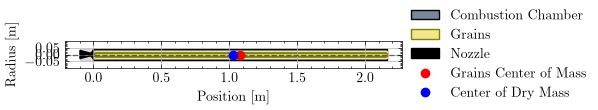

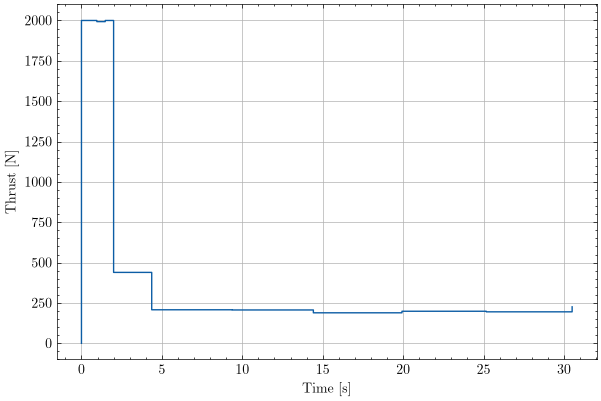

Project-Purple-75mm-Optimal.overview
                       Name  Altitude [km]  Maximum Mach  System Efficiency [%]  Total Impulse [Ns]  Maximum Thrust [N]  Average Thrust [N]  Burn Time [s]
Project-Purple-75mm-Optimal          10.78          0.91                  52.14            10239.02             2000.00              335.62          30.51
Project-Purple-75mm-Optimal.flight-energies
                    Name  Energy [MJ]  % of Thrust
             Thrust Work         2.13       100.00
               Drag Work        -0.75       -35.29
            Gravity Work        -1.23       -57.80
   Other / Residual Work         0.14         6.34
   Apogee Kinetic Energy         0.01         0.57
Ideal Performance Energy        -1.11       -52.14
Project-Purple-75mm-Optimal.flight-event-summary
                    Name  Time [s]  Altitude [km]  Velocity (Up) [m/s]  Acceleration (Up) [g]  Acceleration (+/- 1 s) (Up) [g]
            Launch Point      0.00           0.01                 0.00      

c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\model\util\output\plot.py:820: UserWarning: Encoutered error when arranging figures. 1 figure(s) could not fit on the selected monitor.. Showing without arranging
  warnings.warn(


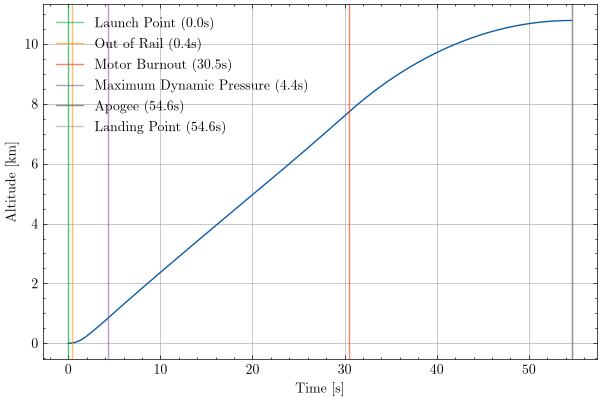

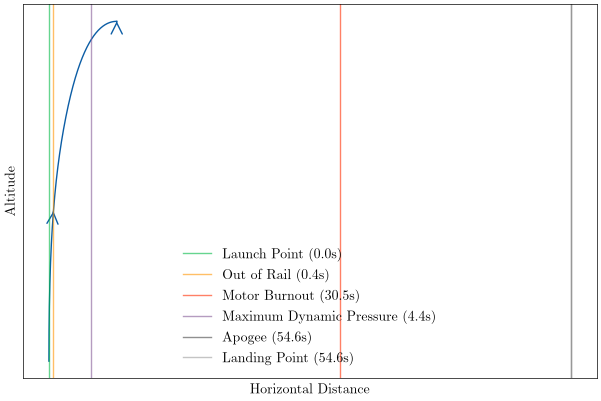

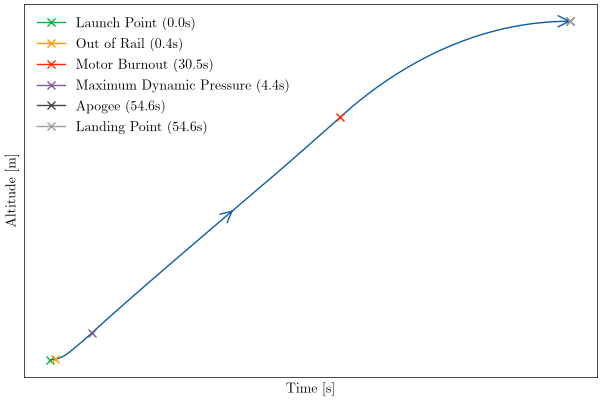

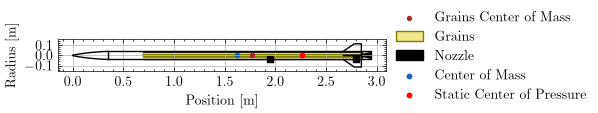

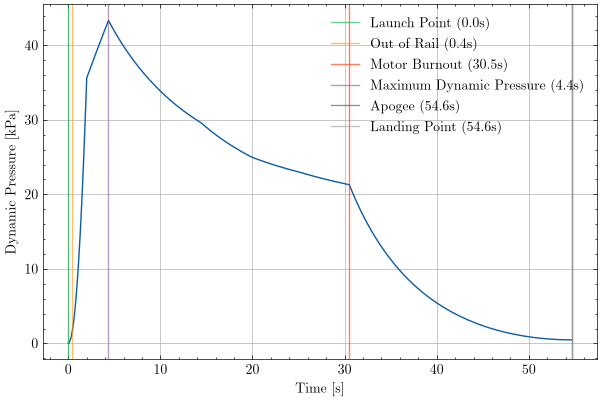

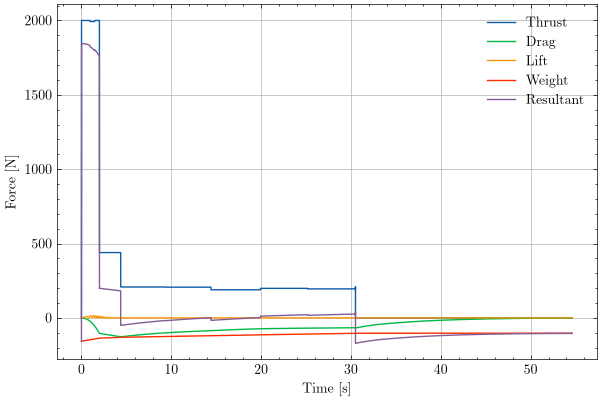

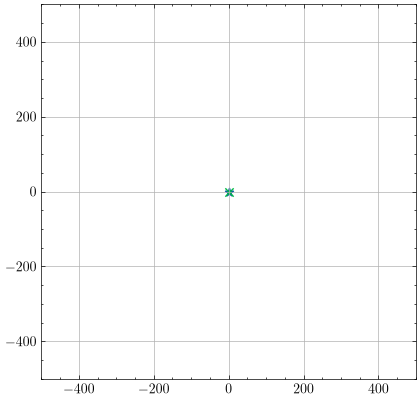

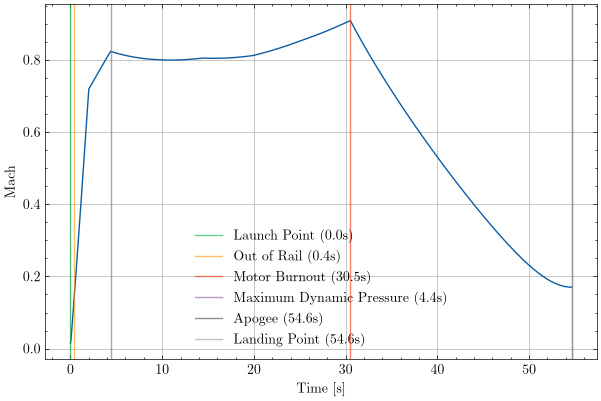

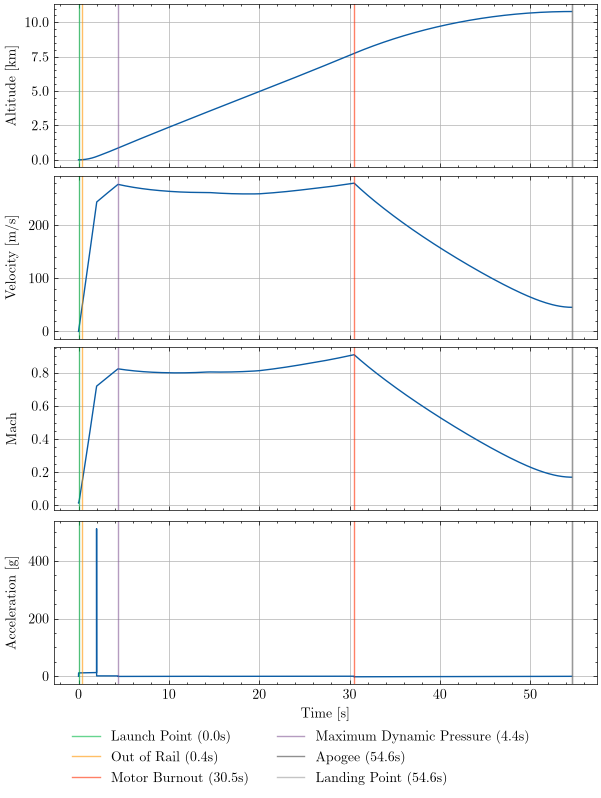

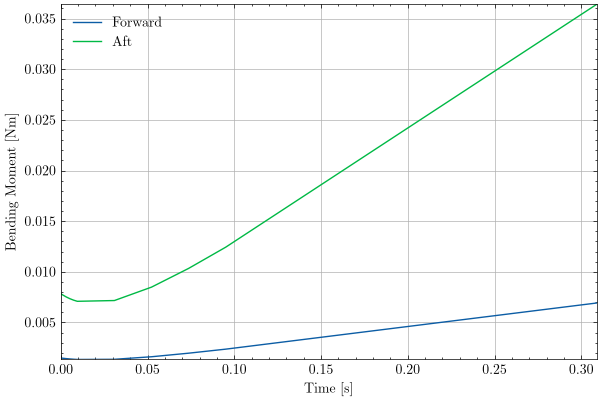

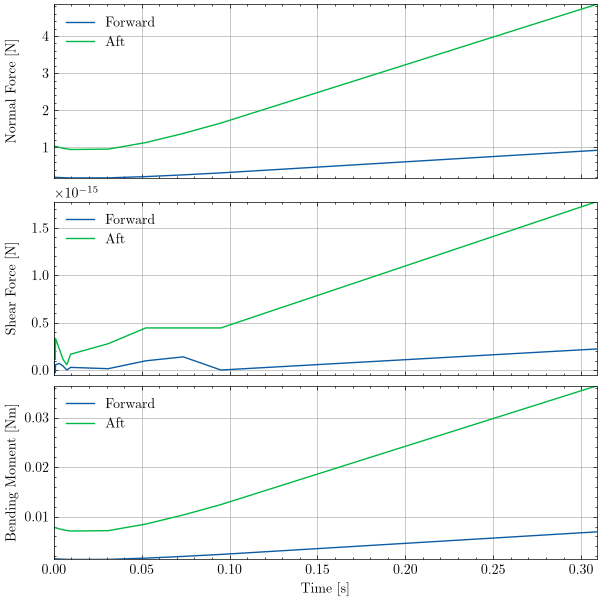

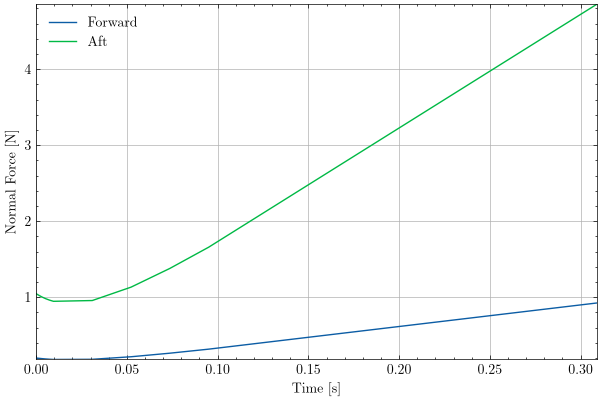

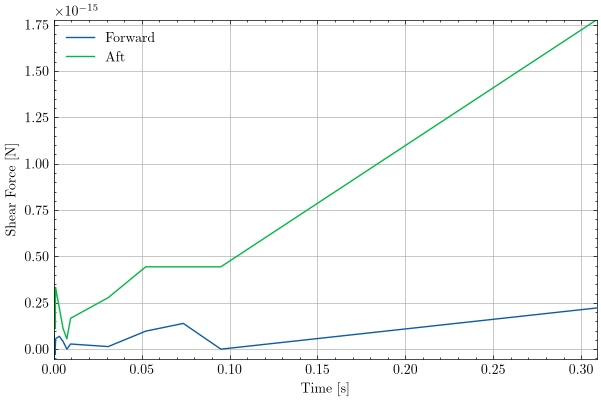

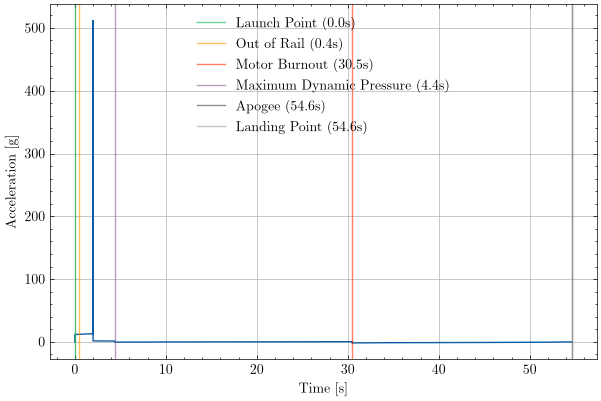

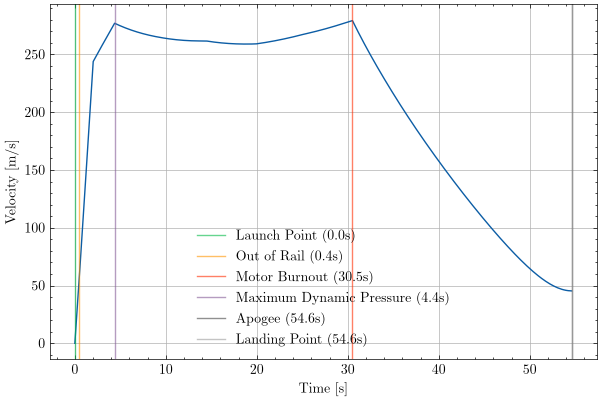

In [10]:
optimal_table: Table | None = None

out = optimiser.optimise_thrust_curve(
    constraints=constraints,
    assumptions=assumptions,
    verbose=False,
    passes_points=[10, 10, 10]
)
if out is None:
    print(f"No valid optimised thrust curve")
else:
    best_flight, best_motor, out_table = out
    optimal_table += out_table

    best_motor.plots.all(show=True, save=save)

assert optimal_table
optimal_table.show(sort_column="Altitude [km]", sort_ascending=False)

best_flight.info.all(show=True, save=save)
best_flight.plots.all(show=True, save=save)

In [11]:
assert fixed_table
assert cots_table
assert optimal_table
table = fixed_table + cots_table + optimal_table

table.show(sort_column="Altitude [km]", sort_ascending=False)
if save:
    table.save(sort_column="Altitude [km]", sort_ascending=False)

Project-Purple-75mm-overview
                                 Name  Altitude [km]  Maximum Mach  System Efficiency [%]  Total Impulse [Ns]  Maximum Thrust [N]  Average Thrust [N]  Burn Time [s]
          Project-Purple-75mm-Optimal          10.78          0.91                  52.14            10239.02             2000.00              335.62          30.51
             Project-Purple-75mm-M795          10.15          1.69                  21.73            10132.80             1721.90              794.11          12.76
           Project-Purple-75mm-M1939W           9.25          2.13                  16.36            10368.56             2229.83             1491.88           6.95
            Project-Purple-75mm-M1450           9.20          2.01                  18.71             9955.75             2410.91             1449.16           6.87
            Project-Purple-75mm-M750W           9.12          1.51                  23.64             9255.91             1217.41              578

c:\Users\rufus\OneDrive - The University of Manchester\Documents\University\Year 4\Advanced Research Project\System Model\model\util\output\base.py:130: UserWarning: Value 'Project-Purple-75mm (overview)' was sanitised to 'Project-Purple-75mm-overview-'
  self._title = self._sanitise(self._title)
